# Balanced arXiv IMSTE experiments

This notebook uses a reproducible subset of the full prepared vector cache so configuration experiments finish quickly. The default is 32,000 unique papers, sampled evenly across the eight domains (4,000 per domain). The requested number per class is capped by the smallest available class. Balanced selection never duplicates papers; change `TARGET_PER_CLASS` or `SAMPLE_MODE` to control the experiment subset.

UMAP is fitted only as a comparison reference. **Every IMSTE run uses PCA/multilevel initialization and is independent of UMAP coordinates.** The experiment matrix checks independent initializations, optimizer and repulsion settings, and local-neighbor graph alternatives. It reports neighborhood fidelity, domain purity, relative local radius, and runtime. Subset and model settings are included in cache identities.

In [1]:
from pathlib import Path
import sys
import json
import hashlib
import time
import numpy as np
import pandas as pd
from IPython.display import display

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "pyproject.toml").exists() and (PROJECT_ROOT.parent / "pyproject.toml").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT / "notebooks" / "src"))
from arxiv_dataset import load_arxiv_dataset
from arxiv_imste import select_arxiv_experiment_subset

DATA_DIR = PROJECT_ROOT / "data" / "arxiv"
CACHE_DIR = DATA_DIR / "cache"
EXPERIMENT_CACHE_DIR = CACHE_DIR / "balanced_experiments"
EXPERIMENT_CACHE_DIR.mkdir(parents=True, exist_ok=True)
papers, X_full, data_manifest = load_arxiv_dataset(DATA_DIR)

primary_category = papers["categories"].fillna("unknown").str.split().str[0]
archive = primary_category.str.split(".").str[0]
domain_names = {
    "cs": "computer science",
    "math": "mathematics",
    "eess": "engineering",
    "stat": "statistics",
    "q-bio": "biology",
    "q-fin": "finance",
    "econ": "economics",
}
domain = archive.map(domain_names).fillna("physics")
domain_order = domain.value_counts().index.tolist()
labels_full = pd.Categorical(domain, categories=domain_order)

# Change these controls to run a smaller, reproducible experiment.
SAMPLE_MODE = "balanced"  # "balanced", "random", or "full"
TARGET_PER_CLASS = 4_000
SAMPLE_RANDOM_STATE = int(data_manifest["random_state"])
if SAMPLE_MODE == "balanced":
    counts = np.unique(np.asarray(labels_full), return_counts=True)[1]
    AVAILABLE_PER_CLASS = int(counts.min())
    PER_CLASS = min(TARGET_PER_CLASS, AVAILABLE_PER_CLASS)
    SAMPLE_SIZE = len(counts) * PER_CLASS
    if PER_CLASS < TARGET_PER_CLASS:
        print(f"Balanced sample capped at {PER_CLASS:,} rows per class by the minority class size.")
else:
    SAMPLE_SIZE = TARGET_PER_CLASS * len(np.unique(np.asarray(labels_full)))
X_experiment, labels_experiment, experiment_data_id = select_arxiv_experiment_subset(
    X_full,
    labels_full,
    dataset_id=data_manifest["dataset_id"],
    mode=SAMPLE_MODE,
    sample_size=SAMPLE_SIZE,
    random_state=SAMPLE_RANDOM_STATE,
)
print(f"Source data: {len(X_full):,} papers × {X_full.shape[1]:,} features")
print(f"Experiment subset: {len(X_experiment):,} rows ({SAMPLE_MODE}), ID {experiment_data_id}")
print(pd.Series(np.asarray(labels_experiment)).value_counts().sort_index().to_string())

# Shared geometry settings. Keep these fixed when comparing initializations.
RANDOM_STATE = int(data_manifest["random_state"])
METRIC = "euclidean"
N_NEIGHBORS = 15
UMAP_EPOCHS = 200
IMSTE_N_MSTS = 5
IMSTE_N_EPOCHS = 100
IMSTE_BATCH_SIZE = 32768
IMSTE_LEARNING_RATE = 0.05
IMSTE_NEGATIVE_RATIO = 1
IMSTE_LAMBDA_REP = 0.05
IMSTE_LOGISTIC_MARGIN = 0.25
IMSTE_LOGISTIC_TEMPERATURE = 0.5
IMSTE_DEVICE = "mps"  # Set to "auto" or "cpu" when MPS is unavailable.
IMSTE_MST_NEIGHBOR_BACKEND = "rinnd"


Source data: 1,200,000 papers × 384 features
Experiment subset: 32,000 rows (balanced), ID c2e0ceee03fc5e6b00b2
biology             4000
computer science    4000
economics           4000
engineering         4000
finance             4000
mathematics         4000
physics             4000
statistics          4000


In [2]:
import umap

umap_settings = {
    "n_components": 2,
    "n_neighbors": N_NEIGHBORS,
    "min_dist": 0.1,
    "repulsion_strength": 4,
    "metric": METRIC,
    "compatibility_layout": False,
    "nearest_neighbor_backend": "rinnd",
    "init": "recursive",
    "random_state": RANDOM_STATE,
    "n_epochs": UMAP_EPOCHS,
}
umap_key = hashlib.sha256(
    json.dumps({"data_id": experiment_data_id, **umap_settings}, sort_keys=True).encode()
).hexdigest()[:16]
umap_cache_path = EXPERIMENT_CACHE_DIR / f"umap_{umap_key}.npz"
if umap_cache_path.is_file():
    saved = np.load(umap_cache_path, allow_pickle=False)
    Z_umap = saved["embedding"]
    umap_seconds = float(saved["seconds"])
    print("Loaded cached subset UMAP:", umap_cache_path.name)
else:
    started = time.perf_counter()
    Z_umap = umap.UMAP(verbose=True, **umap_settings).fit_transform(X_experiment)
    umap_seconds = time.perf_counter() - started
    np.savez_compressed(
        umap_cache_path,
        embedding=np.asarray(Z_umap, dtype=np.float32),
        seconds=np.asarray(umap_seconds),
        settings_json=np.asarray(json.dumps(umap_settings, sort_keys=True)),
        data_id=np.asarray(experiment_data_id),
    )
    print(f"Subset UMAP fit: {umap_seconds:.2f}s")


Loaded cached subset UMAP: umap_ab0482a52f52ecba.npz


In [3]:
from imste import IteratedMinimumSpanningTreeEmbedder
from imste.mst.famst import _ann_edges_rinnd
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components
from sklearn.manifold import SpectralEmbedding

# Independent local-graph spectral initialization (cached by data and settings).
spectral_settings = {"neighbors": N_NEIGHBORS, "affinity": "kth_neighbor_scale_rbf", "random_state": RANDOM_STATE}
spectral_key = hashlib.sha256(
    json.dumps({"data_id": experiment_data_id, **spectral_settings}, sort_keys=True).encode()
).hexdigest()[:16]
spectral_path = EXPERIMENT_CACHE_DIR / f"spectral_init_{spectral_key}.npz"
if spectral_path.is_file():
    Z_spectral = np.load(spectral_path, allow_pickle=False)["embedding"]
    print("Loaded cached spectral initialization:", spectral_path.name)
else:
    edge_map = _ann_edges_rinnd(
        X_experiment, N_NEIGHBORS, RANDOM_STATE, verbose=False
    )
    pairs = np.asarray(list(edge_map), dtype=np.int64)
    distances = np.fromiter(edge_map.values(), dtype=np.float64, count=len(edge_map))
    rows = np.r_[pairs[:, 0], pairs[:, 1]]
    cols = np.r_[pairs[:, 1], pairs[:, 0]]
    distance_graph = coo_matrix(
        (np.r_[distances, distances], (rows, cols)),
        shape=(len(X_experiment), len(X_experiment)),
    ).tocsr()
    local_scale = np.empty(len(X_experiment), dtype=np.float64)
    for node in range(len(X_experiment)):
        incident = distance_graph.data[
            distance_graph.indptr[node] : distance_graph.indptr[node + 1]
        ]
        rank = min(N_NEIGHBORS, len(incident)) - 1
        local_scale[node] = np.partition(incident, rank)[rank]
    affinity = np.exp(
        -(distances**2)
        / np.maximum(local_scale[pairs[:, 0]] * local_scale[pairs[:, 1]], 1e-12)
    )
    weights = np.r_[affinity, affinity]
    neighborhood_graph = coo_matrix(
        (weights, (rows, cols)), shape=(len(X_experiment), len(X_experiment))
    ).tocsr()
    components = connected_components(neighborhood_graph, directed=False, return_labels=False)
    if components != 1:
        raise RuntimeError(f"Spectral initialization graph has {components} components.")
    Z_spectral = SpectralEmbedding(
        n_components=2, affinity="precomputed", eigen_solver="lobpcg", eigen_tol=1e-3,
        random_state=RANDOM_STATE,
    ).fit_transform(neighborhood_graph)
    Z_spectral /= max(float(np.max(np.abs(Z_spectral))), 1e-12)
    np.savez_compressed(
        spectral_path, embedding=np.asarray(Z_spectral, dtype=np.float32),
        settings_json=np.asarray(json.dumps(spectral_settings, sort_keys=True)),
        data_id=np.asarray(experiment_data_id),
    )
    print(f"Spectral initialization fit: {spectral_path.name}")

IMSTE_COMMON_SETTINGS = {
    "n_components": 2,
    "n_msts": IMSTE_N_MSTS,
    "n_epochs": IMSTE_N_EPOCHS,
    "batch_size": IMSTE_BATCH_SIZE,
    "learning_rate": IMSTE_LEARNING_RATE,
    "negative_ratio": IMSTE_NEGATIVE_RATIO,
    "lambda_rep": IMSTE_LAMBDA_REP,
    "random_state": RANDOM_STATE,
    "device": IMSTE_DEVICE,
    "logistic_margin": IMSTE_LOGISTIC_MARGIN,
    "logistic_temperature": IMSTE_LOGISTIC_TEMPERATURE,
    "mst_method": "famst",
    "mst_neighbor_backend": IMSTE_MST_NEIGHBOR_BACKEND,
    "mst_neighbors": N_NEIGHBORS,
    "mst_inter_component_edges": 5,
    "mst_representatives_per_component": 10,
    "mst_max_neighbors": None,
    "include_knn_attraction": False,
    "pca_init": True,
    "pca_init_scaling": "global",
    "multilevel_init": True,
    "multilevel_reduction_ratio": 8,
    "multilevel_base_size": 512,
    "multilevel_epochs": 10,
    "metric": METRIC,
    "verbose": False,
}

def fit_imste_variant(name, overrides=None, init_coordinates=None, init_id=None):
    settings = {**IMSTE_COMMON_SETTINGS, **(overrides or {}), "init_coordinates_id": init_id}
    key = hashlib.sha256(
        json.dumps(
            {"data_id": experiment_data_id, "name": name, "settings": settings},
            sort_keys=True,
        ).encode()
    ).hexdigest()[:16]
    path = EXPERIMENT_CACHE_DIR / f"imste_{key}.npz"
    if path.is_file():
        saved = np.load(path, allow_pickle=False)
        print(f"Loaded cached {name}: {path.name}")
        return saved["embedding"], float(saved["seconds"])

    estimator_settings = {key: value for key, value in settings.items() if key != "init_coordinates_id"}
    if init_coordinates is not None:
        estimator_settings["init_coordinates"] = init_coordinates
    started = time.perf_counter()
    estimator = IteratedMinimumSpanningTreeEmbedder(**estimator_settings)
    embedding = estimator.fit_transform(X_experiment)
    seconds = time.perf_counter() - started
    np.savez_compressed(
        path,
        embedding=np.asarray(embedding, dtype=np.float32),
        seconds=np.asarray(seconds),
        settings_json=np.asarray(json.dumps(settings, sort_keys=True)),
        data_id=np.asarray(experiment_data_id),
    )
    print(f"{name} fit: {seconds:.2f}s")
    return embedding, seconds

from imste.mst import build_mst_edges
from imste._estimator import _append_candidate_attraction_edges
from imste._estimator import _standardized_pca_initialization, _scale_initialization_coordinates
from imste._optimizer import optimize_embedding

def fit_weighted_knn_variant(strength):
    """Fit IMSTE on inverse-rank MST edges plus local-scale weighted ANN edges."""
    name = f"weighted_knn_strength_{strength:g}"
    init_settings = {
        **IMSTE_COMMON_SETTINGS,
        "n_epochs": IMSTE_N_EPOCHS,
        "knn_weight_sum_to_mst_weight_sum": float(strength),
        "init": "standardized_pca",
        "implementation": 2,
    }
    key = hashlib.sha256(json.dumps(
        {"data_id": experiment_data_id, "name": name, "settings": init_settings},
        sort_keys=True,
    ).encode()).hexdigest()[:16]
    path = EXPERIMENT_CACHE_DIR / f"weighted_{key}.npz"
    if path.is_file():
        saved = np.load(path, allow_pickle=False)
        print(f"Loaded cached {name}: {path.name}")
        return saved["embedding"], float(saved["seconds"])

    started = time.perf_counter()
    candidate_batches = []
    mst_edges, mst_ranks = build_mst_edges(
        X_experiment,
        n_msts=IMSTE_N_MSTS,
        random_state=RANDOM_STATE,
        method="famst",
        neighbors=N_NEIGHBORS,
        inter_component_edges=5,
        max_neighbors=None,
        representatives_per_component=10,
        neighbor_device=IMSTE_DEVICE,
        neighbor_backend=IMSTE_MST_NEIGHBOR_BACKEND,
        return_ranks=True,
        metric=METRIC,
        candidate_edges_callback=candidate_batches.append,
    )
    candidate_edges = np.sort(np.asarray(candidate_batches[-1], dtype=np.int64), axis=1)
    n_samples = len(X_experiment)

    # Compute exact candidate-edge distances in bounded memory.
    candidate_distances = np.empty(len(candidate_edges), dtype=np.float64)
    for start in range(0, len(candidate_edges), 8192):
        stop = min(start + 8192, len(candidate_edges))
        delta = (
            np.asarray(X_experiment[candidate_edges[start:stop, 0]], dtype=np.float32)
            - np.asarray(X_experiment[candidate_edges[start:stop, 1]], dtype=np.float32)
        )
        candidate_distances[start:stop] = np.sqrt(np.einsum("ij,ij->i", delta, delta))

    rows = np.r_[candidate_edges[:, 0], candidate_edges[:, 1]]
    cols = np.r_[candidate_edges[:, 1], candidate_edges[:, 0]]
    distance_graph = coo_matrix(
        (np.r_[candidate_distances, candidate_distances], (rows, cols)),
        shape=(n_samples, n_samples),
    ).tocsr()
    local_rho = np.empty(n_samples, dtype=np.float64)
    local_sigma = np.empty(n_samples, dtype=np.float64)
    for node in range(n_samples):
        incident = distance_graph.data[
            distance_graph.indptr[node] : distance_graph.indptr[node + 1]
        ]
        ordered = np.partition(incident, min(N_NEIGHBORS, len(incident)) - 1)
        local_rho[node] = ordered[0]
        local_sigma[node] = max(ordered[min(N_NEIGHBORS, len(incident)) - 1] - ordered[0], 1e-8)
    left, right = candidate_edges.T
    left_membership = np.exp(-np.maximum(candidate_distances - local_rho[left], 0.0) / local_sigma[left])
    right_membership = np.exp(-np.maximum(candidate_distances - local_rho[right], 0.0) / local_sigma[right])
    candidate_weights = left_membership + right_membership - left_membership * right_membership

    mst_edges = np.sort(np.asarray(mst_edges, dtype=np.int64), axis=1)
    mst_keys = mst_edges[:, 0] * n_samples + mst_edges[:, 1]
    candidate_keys = candidate_edges[:, 0] * n_samples + candidate_edges[:, 1]
    unique_keys = np.union1d(mst_keys, candidate_keys)
    edge_weights = np.zeros(len(unique_keys), dtype=np.float64)
    np.add.at(edge_weights, np.searchsorted(unique_keys, mst_keys), 1.0 / mst_ranks)
    mst_weight_sum = float(np.sum(1.0 / mst_ranks))
    candidate_weights *= float(strength) * mst_weight_sum / max(float(candidate_weights.sum()), 1e-12)
    np.add.at(edge_weights, np.searchsorted(unique_keys, candidate_keys), candidate_weights)
    combined_edges = np.column_stack((unique_keys // n_samples, unique_keys % n_samples))

    coordinates = _standardized_pca_initialization(X_experiment, 2, RANDOM_STATE)
    coordinates = _scale_initialization_coordinates(coordinates, "global").astype(np.float32)
    seed_rng = np.random.RandomState(RANDOM_STATE)
    optimizer_seed = int(seed_rng.randint(0, np.iinfo(np.int32).max))
    kwargs = dict(
        n_epochs=IMSTE_N_EPOCHS,
        learning_rate=IMSTE_LEARNING_RATE,
        negative_ratio=IMSTE_NEGATIVE_RATIO,
        lambda_rep=IMSTE_LAMBDA_REP,
        epsilon=1e-4,
        margin=IMSTE_LOGISTIC_MARGIN,
        temperature=IMSTE_LOGISTIC_TEMPERATURE,
        random_state=optimizer_seed,
        schedule_by_rank=False,
        edge_weights=edge_weights,
    )
    if IMSTE_DEVICE == "mps":
        from imste._optimizer_mps import optimize_embedding_mps
        optimize_embedding_mps(
            coordinates, combined_edges, np.ones(len(combined_edges), dtype=np.int32),
            batch_size=IMSTE_BATCH_SIZE, **kwargs,
        )
    else:
        optimize_embedding(
            coordinates, combined_edges, np.ones(len(combined_edges), dtype=np.int32),
            **kwargs,
        )
    seconds = time.perf_counter() - started
    np.savez_compressed(
        path,
        embedding=coordinates,
        seconds=np.asarray(seconds),
        settings_json=np.asarray(json.dumps(init_settings, sort_keys=True)),
        data_id=np.asarray(experiment_data_id),
    )
    print(f"{name} fit: {seconds:.2f}s ({len(combined_edges):,} weighted edges)")
    return coordinates, seconds


def fit_neighbor_graph_multilevel_init():
    """Use local ANN edges only for coarsening/refinement, then optimize the MST."""
    name = "mst_objective_neighbor_graph_multilevel_init"
    settings = {**IMSTE_COMMON_SETTINGS, "multilevel_init_graph": "mst_plus_ann", "implementation": 2}
    key = hashlib.sha256(json.dumps(
        {"data_id": experiment_data_id, "name": name, "settings": settings},
        sort_keys=True,
    ).encode()).hexdigest()[:16]
    path = EXPERIMENT_CACHE_DIR / f"imste_{key}.npz"
    if path.is_file():
        saved = np.load(path, allow_pickle=False)
        print(f"Loaded cached {name}: {path.name}")
        return saved["embedding"], float(saved["seconds"])

    started = time.perf_counter()
    candidate_batches = []
    graph_estimator = IteratedMinimumSpanningTreeEmbedder(**IMSTE_COMMON_SETTINGS)
    options = graph_estimator._validated_fit_options()
    graph_estimator._activate_progress_reporting()
    mst_edges, mst_ranks = build_mst_edges(
        X_experiment,
        n_msts=IMSTE_N_MSTS,
        random_state=RANDOM_STATE,
        method="famst",
        neighbors=N_NEIGHBORS,
        inter_component_edges=5,
        max_neighbors=None,
        representatives_per_component=10,
        neighbor_device=IMSTE_DEVICE,
        neighbor_backend=IMSTE_MST_NEIGHBOR_BACKEND,
        return_ranks=True,
        metric=METRIC,
        candidate_edges_callback=candidate_batches.append,
    )
    init_edges, init_ranks = _append_candidate_attraction_edges(
        mst_edges, mst_ranks, candidate_batches[-1], len(X_experiment)
    )
    init_coordinates = graph_estimator._multilevel_initialization(
        len(X_experiment), 2, init_edges, init_ranks, options["resolved_device"],
        X_experiment, options,
    )
    if init_coordinates is None:
        raise RuntimeError("Neighbor-graph multilevel initialization produced no hierarchy.")

    estimator = IteratedMinimumSpanningTreeEmbedder(
        **IMSTE_COMMON_SETTINGS, init_coordinates=init_coordinates
    )
    embedding = estimator.fit_transform(X_experiment)
    seconds = time.perf_counter() - started
    np.savez_compressed(
        path,
        embedding=np.asarray(embedding, dtype=np.float32),
        seconds=np.asarray(seconds),
        settings_json=np.asarray(json.dumps(settings, sort_keys=True)),
        data_id=np.asarray(experiment_data_id),
    )
    print(f"{name} fit: {seconds:.2f}s")
    return embedding, seconds


Loaded cached spectral initialization: spectral_init_c437578ffb1d2a00.npz


In [4]:
# Each IMSTE variant starts independently; none uses UMAP coordinates.
# Change one optimizer/graph/initialization setting at a time.
Z_imste_baseline, imste_baseline_seconds = fit_imste_variant("pca_mst_baseline")
Z_imste_spectral, imste_spectral_seconds = fit_imste_variant(
    "pca_mst_spectral_init", init_coordinates=Z_spectral, init_id=spectral_key
)
Z_imste_pca_only, imste_pca_only_seconds = fit_imste_variant(
    "pca_only", {"multilevel_init": False}
)
Z_imste_500_epochs, imste_500_epochs_seconds = fit_imste_variant(
    "pca_mst_500_epochs", {"n_epochs": 500}
)
Z_imste_lr01, imste_lr01_seconds = fit_imste_variant(
    "pca_mst_lr001", {"learning_rate": 0.01}
)
Z_imste_repulsion_001, imste_repulsion_001_seconds = fit_imste_variant(
    "pca_mst_repulsion_001", {"lambda_rep": 0.01}
)
Z_imste_repulsion_01, imste_repulsion_01_seconds = fit_imste_variant(
    "pca_mst_repulsion_01", {"lambda_rep": 0.1}
)
Z_imste_repulsion_02, imste_repulsion_02_seconds = fit_imste_variant(
    "pca_mst_repulsion_02", {"lambda_rep": 0.2}
)
Z_imste_wider_margin, imste_wider_margin_seconds = fit_imste_variant(
    "pca_mst_margin_05", {"logistic_margin": 0.5}
)
Z_imste_mst15, imste_mst15_seconds = fit_imste_variant(
    "pca_mst_15_trees", {"n_msts": 15}
)
Z_imste_neighbors30, imste_neighbors30_seconds = fit_imste_variant(
    "pca_mst_neighbors30", {"mst_neighbors": 30}
)
Z_imste_neighbors50, imste_neighbors50_seconds = fit_imste_variant(
    "pca_mst_neighbors50", {"mst_neighbors": 50}
)
Z_imste_knn, imste_knn_seconds = fit_imste_variant(
    "pca_mst_plus_candidate_neighbors", {"include_knn_attraction": True}
)
Z_weighted_knn_025, weighted_knn_025_seconds = fit_weighted_knn_variant(0.25)
Z_weighted_knn_1, weighted_knn_1_seconds = fit_weighted_knn_variant(1.0)
Z_weighted_knn_4, weighted_knn_4_seconds = fit_weighted_knn_variant(4.0)

Z_imste_knn_multilevel, imste_knn_multilevel_seconds = fit_neighbor_graph_multilevel_init()


Loaded cached pca_mst_baseline: imste_bc84b5da2f68f374.npz
Loaded cached pca_mst_spectral_init: imste_fdf94ccd143f4663.npz
Loaded cached pca_only: imste_03c0747a6a9fd086.npz
Loaded cached pca_mst_500_epochs: imste_0b164705901f85e3.npz
Loaded cached pca_mst_lr001: imste_18d4ee67089132e3.npz
Loaded cached pca_mst_repulsion_001: imste_0b426ff958cc8db0.npz
Loaded cached pca_mst_repulsion_01: imste_339ee58cbaec17a2.npz
Loaded cached pca_mst_repulsion_02: imste_b5d0dc6ef440a086.npz
Loaded cached pca_mst_margin_05: imste_19ff823cdd949396.npz
Loaded cached pca_mst_15_trees: imste_1293c665046913f6.npz
Loaded cached pca_mst_neighbors30: imste_c3de5bc4a18b4761.npz
Loaded cached pca_mst_neighbors50: imste_8c70997c7ce0aaa3.npz
Loaded cached pca_mst_plus_candidate_neighbors: imste_8b68e721766ebf74.npz
Loaded cached weighted_knn_strength_0.25: weighted_ccc5e616016f91e5.npz
Loaded cached weighted_knn_strength_1: weighted_971667930ffd164f.npz
Loaded cached weighted_knn_strength_4: weighted_fd2f1c8613cf

In [5]:
from sklearn.manifold import trustworthiness
from sklearn.neighbors import NearestNeighbors

METRIC_ANCHORS = min(2_000, len(X_experiment))
METRIC_K = min(15, max(1, len(X_experiment) // 2))
metric_rng = np.random.RandomState(2027)
anchor_indices = np.sort(metric_rng.choice(len(X_experiment), METRIC_ANCHORS, replace=False))
input_index = NearestNeighbors(n_neighbors=METRIC_K + 1, algorithm="brute", n_jobs=-1).fit(X_experiment)
input_neighbors = input_index.kneighbors(X_experiment[anchor_indices], return_distance=False)

def _without_self(neighbor_rows, query_indices, k):
    cleaned = []
    for row, query_index in zip(neighbor_rows, query_indices):
        cleaned.append([int(index) for index in row if index != query_index][:k])
    return cleaned

input_neighbors = _without_self(input_neighbors, anchor_indices, METRIC_K)
anchor_labels = np.asarray(labels_experiment)[anchor_indices]

def score_layout(name, coordinates):
    layout_index = NearestNeighbors(n_neighbors=METRIC_K + 1, algorithm="kd_tree", n_jobs=-1).fit(coordinates)
    distances, neighbor_rows = layout_index.kneighbors(coordinates[anchor_indices], return_distance=True)
    cleaned = _without_self(neighbor_rows, anchor_indices, METRIC_K)
    cleaned_distances = []
    for row, query_index in zip(neighbor_rows, anchor_indices):
        keep = row != query_index
        cleaned_distances.append(distances[len(cleaned_distances), keep][:METRIC_K])
    overlap = np.mean([
        len(set(source).intersection(target)) / METRIC_K
        for source, target in zip(input_neighbors, cleaned)
    ])
    neighbors = np.asarray(cleaned, dtype=np.int64)
    purity = float(np.mean(np.asarray(labels_experiment)[neighbors] == anchor_labels[:, None]))
    macro_purity = float(np.mean([
        np.mean(np.asarray(labels_experiment)[neighbors[anchor_labels == label]] == label)
        for label in np.unique(anchor_labels)
        if np.any(anchor_labels == label)
    ]))
    local_radius = float(np.median(np.asarray(cleaned_distances)[:, -1]))
    center = np.median(coordinates, axis=0)
    extent = float(np.median(np.linalg.norm(coordinates[anchor_indices] - center, axis=1)))
    with np.errstate(over="ignore", divide="ignore", invalid="ignore"):
        trust = trustworthiness(
            X_experiment[trust_indices], coordinates[trust_indices], n_neighbors=METRIC_K
        )
    return {
        "layout": name,
        "trustworthiness": float(trust),
        "input_neighbor_overlap@15": float(overlap),
        "domain_purity@15": purity,
        "macro_domain_purity@15": macro_purity,
        "median_15NN_radius / median_extent": local_radius / max(extent, 1e-12),
    }

trust_indices = np.sort(metric_rng.choice(len(X_experiment), min(1_500, len(X_experiment)), replace=False))

score_rows = [
    score_layout("UMAP · reference", Z_umap),
    score_layout("IMSTE · PCA/multilevel", Z_imste_baseline),
    score_layout("IMSTE · spectral init + MST", Z_imste_spectral),
    score_layout("IMSTE · ANN multilevel init, MST objective", Z_imste_knn_multilevel),
    score_layout("IMSTE · PCA only", Z_imste_pca_only),
    score_layout("IMSTE · PCA/multilevel, 500 epochs", Z_imste_500_epochs),
    score_layout("IMSTE · lr=0.01", Z_imste_lr01),
    score_layout("IMSTE · repulsion=0.01", Z_imste_repulsion_001),
    score_layout("IMSTE · repulsion=0.10", Z_imste_repulsion_01),
    score_layout("IMSTE · repulsion=0.20", Z_imste_repulsion_02),
    score_layout("IMSTE · margin=0.5", Z_imste_wider_margin),
    score_layout("IMSTE · 15 MSTs", Z_imste_mst15),
    score_layout("IMSTE · 30 candidate neighbors", Z_imste_neighbors30),
    score_layout("IMSTE · 50 candidate neighbors", Z_imste_neighbors50),
    score_layout("IMSTE · MST + neighbor attractions", Z_imste_knn),
    score_layout("IMSTE · weighted ANN, 0.25× MST weight", Z_weighted_knn_025),
    score_layout("IMSTE · weighted ANN, 1× MST weight", Z_weighted_knn_1),
    score_layout("IMSTE · weighted ANN, 4× MST weight", Z_weighted_knn_4),
]
scores = pd.DataFrame(score_rows)
display(scores)


,layout,trustworthiness,input_neighbor_overlap@15,domain_purity@15,macro_domain_purity@15,median_15NN_radius / median_extent
0,UMAP · reference,0.926169,0.212267,0.710333,0.708645,0.010861
1,IMSTE · PCA/multilevel,0.824666,0.053833,0.603100,0.597588,0.016352
2,IMSTE · spectral init + MST,0.831388,0.055667,0.599300,0.594263,0.021841
3,"IMSTE · ANN multilevel init, MST objective",0.821193,0.053567,0.596633,0.590208,0.017042
4,IMSTE · PCA only,0.828482,0.054100,0.593767,0.588452,0.017821
5,"IMSTE · PCA/multilevel, 500 epochs",0.831439,0.056733,0.620933,0.615875,0.017992
6,IMSTE · lr=0.01,0.823599,0.050667,0.589200,0.582971,0.017702
7,IMSTE · repulsion=0.01,0.818903,0.051433,0.596667,0.590385,0.020319
8,IMSTE · repulsion=0.10,0.833013,0.057033,0.610467,0.605488,0.019083
9,IMSTE · repulsion=0.20,0.840817,0.060300,0.624133,0.619635,0.022030


## Current independent IMSTE results

On the deterministic balanced 32k subset, the UMAP reference scored 0.926 trustworthiness, 0.212 input 15-NN overlap, 0.710 domain purity, and 0.0109 normalized local radius. The standard independent IMSTE baseline scored 0.825, 0.054, 0.603, and 0.0164 respectively.

No tested IMSTE configuration has matched UMAP's local fidelity and compactness. The highest IMSTE trustworthiness came from `lambda_rep=0.2` (0.841 trustworthiness, 0.060 overlap, 0.624 purity, 0.0220 radius), with substantially worse compactness and fidelity than UMAP. Raising epochs to 500 improved trustworthiness only to 0.831 and increased radius to 0.0180. Increasing candidate neighbors to 30 or 50 had little effect. A spectral initialization scored 0.831 trustworthiness but had a 0.0218 radius. Using ANN edges to construct the multilevel start slightly reduced radius to 0.0170, but trustworthiness and domain purity fell. Weighted ANN attractions took about 5.2s end-to-end versus 2.9s for the baseline and did not improve the overall tradeoff.

These controlled results rule out simple repulsion, epoch-count, neighbor-count, and initialization changes as sufficient fixes. **The fan-shaped independent IMSTE layout is still unresolved.** The next useful work is a change to the graph optimization objective or edge scheduling, followed by confirmation on the full 640k subset; these 32k diagnostics are for screening only. No UMAP coordinates are used to initialize an IMSTE run.

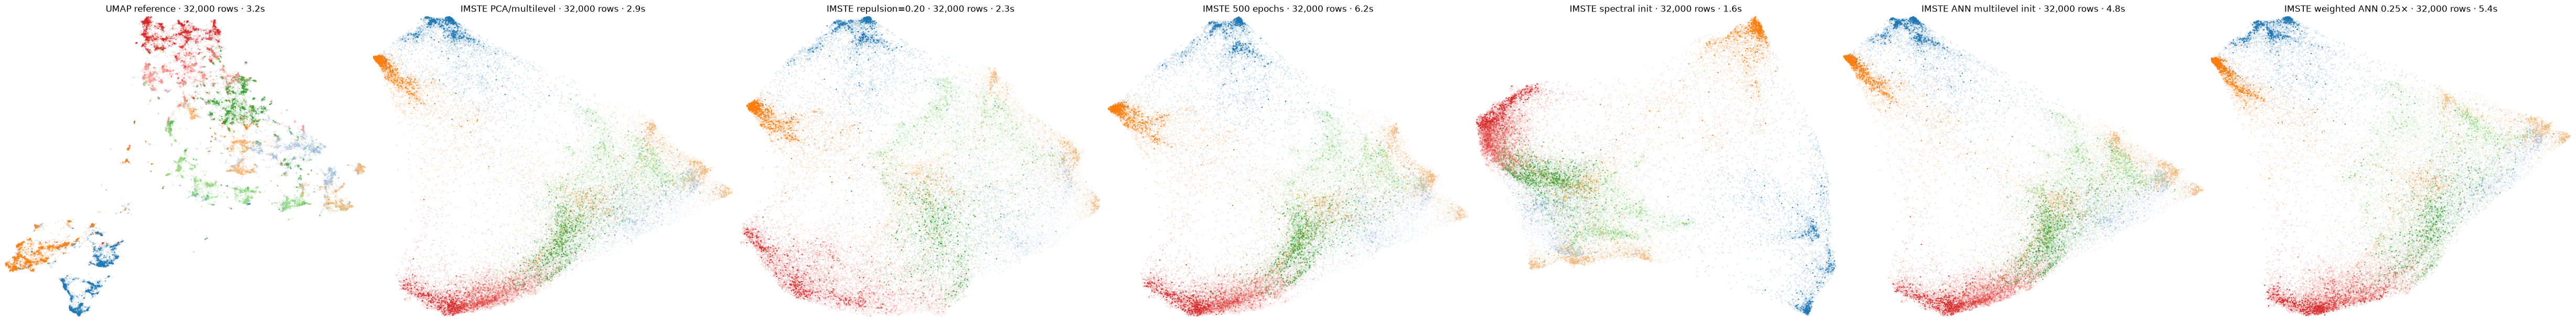

In [6]:
import matplotlib.pyplot as plt
from matplotlib.colors import to_hex
from IPython.display import display
from imste.visualization import render_datashader_embedding

palette = plt.get_cmap("tab20")
class_order = list(labels_experiment.categories)
color_key = {label: to_hex(palette(i % palette.N)) for i, label in enumerate(class_order)}
label_values = pd.Series(np.asarray(labels_experiment)).astype(str)
layouts = [
    ("UMAP reference", Z_umap, umap_seconds),
    ("IMSTE PCA/multilevel", Z_imste_baseline, imste_baseline_seconds),
    ("IMSTE repulsion=0.20", Z_imste_repulsion_02, imste_repulsion_02_seconds),
    ("IMSTE 500 epochs", Z_imste_500_epochs, imste_500_epochs_seconds),
    ("IMSTE spectral init", Z_imste_spectral, imste_spectral_seconds),
    ("IMSTE ANN multilevel init", Z_imste_knn_multilevel, imste_knn_multilevel_seconds),
    ("IMSTE weighted ANN 0.25×", Z_weighted_knn_025, weighted_knn_025_seconds),
]
fig, axes = plt.subplots(1, len(layouts), figsize=(7 * len(layouts), 6), constrained_layout=True)
for ax, (name, coordinates, seconds) in zip(np.atleast_1d(axes), layouts):
    image = render_datashader_embedding(
        coordinates[:, :2], label_values, width=900, height=750,
        color_key=color_key, min_alpha=40, background="white", spread_px=1,
    )
    ax.imshow(image.to_pil())
    ax.set_title(f"{name} · {len(X_experiment):,} rows · {seconds:.1f}s")
    ax.set_axis_off()
display(fig)
plt.close(fig)
